# 02 · Temperature prediction (1-day and 3-day)

**Task:** forecast mean 2 m air temperature for the next day and three days ahead,
per region, from the model-ready panel.

**Why this is a good first forecasting task:** air temperature is the most
autocorrelated variable in the archive. Tomorrow's temperature is close to today's, so
*persistence* is a genuinely strong baseline — the literature on short-range
temperature forecasting consistently finds that machine learning beats it only
marginally at 1–3 days, and mostly by capturing the diurnal and seasonal cycle rather
than any new information.

That framing matters: a model reporting R² = 0.95 looks impressive until you see
persistence already scores 0.94. Every result below is therefore reported **against
persistence**, and the interesting question is not "can we predict temperature" (yes,
trivially) but "do these features add anything to what a thermometer already told us".

Outputs: `temperature_scores.csv`, forecast-vs-observed figure.

In [1]:
# --- shared setup -----------------------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA = Path(os.environ.get("BH6_DATA", r"C:\Users\muhai\Desktop\BIG hero 6\Data"))
MR = DATA / "model_ready"
OUT = Path(os.environ.get("BH6_OUT", str(Path.cwd() / "outputs")))
OUT.mkdir(parents=True, exist_ok=True)

regions = ["Northwest_Rajshahi", "North_Rangpur", "Central_Dhaka", "Northeast_Sylhet",
           "Southwest_Khulna", "South_Barishal", "Southeast_Chattogram"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
SEQ = LinearSegmentedColormap.from_list("brand_blue", ["#eaf2fc", "#9cc3ef", "#2a78d6", "#12365f"])

def pretty(region):
    return region.replace("_", " ")

def load_daily():
    df = pd.read_csv(MR / "daily_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def load_monthly():
    df = pd.read_csv(MR / "monthly_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def split_by_date(dates, train_end="2024-12-31", valid_end="2025-12-31"):
    d = pd.to_datetime(dates)
    return (d <= train_end), (d > train_end) & (d <= valid_end), d > valid_end

def metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    if ok.sum() < 5:
        return {"n": int(ok.sum())}
    return {"n": int(ok.sum()),
            "MAE": round(float(mean_absolute_error(y_true[ok], y_pred[ok])), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y_true[ok], y_pred[ok]))), 3),
            "R2": round(float(r2_score(y_true[ok], y_pred[ok])), 3)}

print(f"pandas {pd.__version__} | data: {DATA}")


pandas 3.1.1 | data: C:\Users\muhai\Desktop\BIG hero 6\Data


## 1. Build the targets

Targets are explicit forward shifts within each region. A 3-day-ahead target uses only
data up to day t, so there is no leakage across the horizon.

In [2]:
daily = load_daily()
g = daily.groupby("region", group_keys=False)
daily["t_plus1"] = g["t2m_c"].shift(-1)
daily["t_plus3"] = g["t2m_c"].shift(-3)

print("rows:", len(daily), "| regions:", daily.region.nunique())
print("1-day target available:", int(daily.t_plus1.notna().sum()))
print("3-day target available:", int(daily.t_plus3.notna().sum()))
daily[["date", "region", "t2m_c", "t_plus1", "t_plus3"]].head()

rows: 12313 | regions: 7
1-day target available: 12285
3-day target available: 12271


,date,region,t2m_c,t_plus1,t_plus3
0,2022-01-01,Central_Dhaka,16.96,17.11,16.42
1,2022-01-02,Central_Dhaka,17.11,16.98,17.14
2,2022-01-03,Central_Dhaka,16.98,16.42,18.02
3,2022-01-04,Central_Dhaka,16.42,17.14,18.44
4,2022-01-05,Central_Dhaka,17.14,18.02,18.58


## 2. Features

Only same-day or past information: today's temperature, the last few days, humidity,
wind, radiation, the seasonal position, and the region. Nothing from t+1 onward.

In [3]:
def feature_frame(df):
    X = df[["t2m_c", "tmax_c", "tmin_c", "diurnal_range_c", "rh_pct", "wind_ms",
            "solar_mj_m2", "pressure_kpa", "vpd_kpa", "power_rain_mm", "gpm_rain_mm",
            "doy_sin", "doy_cos"]].copy()
    past = df.groupby("region", group_keys=False)
    for lag in (1, 2, 3, 7):
        X[f"t2m_lag{lag}"] = past["t2m_c"].shift(lag)
    X["t2m_mean7"] = past["t2m_c"].apply(lambda s: s.rolling(7, min_periods=3).mean())
    X = pd.concat([X, pd.get_dummies(df["region"], prefix="region", dtype=float)], axis=1)
    return X

X_all = feature_frame(daily)
print("feature matrix:", X_all.shape)
X_all.iloc[:3, :8]

feature matrix: (12313, 25)


,t2m_c,tmax_c,tmin_c,diurnal_range_c,rh_pct,wind_ms,solar_mj_m2,pressure_kpa
0,16.96,24.09,11.35,12.74,81.15,1.53,14.63,101.70
1,17.11,23.37,11.22,12.15,81.11,1.39,10.64,101.56
2,16.98,23.21,11.45,11.76,81.81,1.38,14.08,101.50


## 3. Time-based split and baselines

Train on 2022–2024, validate on 2025, test on 2026. Splitting randomly would let the
model interpolate between neighbouring days and report a fiction.

Two baselines: **persistence** (tomorrow = today) and **climatology** (the long-run
mean for that calendar month).

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train, valid, test = split_by_date(daily["date"])
print("train", int(train.sum()), "valid", int(valid.sum()), "test", int(test.sum()))

records = []
models = {}
for horizon, target in [(1, "t_plus1"), (3, "t_plus3")]:
    usable = daily[target].notna()
    tr, te = train & usable, test & usable

    Xtr, ytr = X_all[tr], daily.loc[tr, target]
    Xte, yte = X_all[te], daily.loc[te, target]

    # baselines
    persistence = daily.loc[te, "t2m_c"]          # tomorrow = today
    clim = ytr.groupby(daily.loc[tr, "date"].dt.month).mean()
    climatology = daily.loc[te, "date"].dt.month.map(clim)

    records.append({"horizon": horizon, "model": "persistence", **metrics(yte, persistence)})
    records.append({"horizon": horizon, "model": "climatology", **metrics(yte, climatology)})

    ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))
    ridge.fit(Xtr, ytr)
    records.append({"horizon": horizon, "model": "ridge", **metrics(yte, ridge.predict(Xte))})

    gbr = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, min_samples_leaf=20,
                                        l2_regularization=1.0, random_state=0)
    gbr.fit(Xtr, ytr)
    records.append({"horizon": horizon, "model": "gradient boosting", **metrics(yte, gbr.predict(Xte))})
    models[horizon] = (gbr, Xte, yte, persistence)

scores = pd.DataFrame(records)
scores.to_csv(OUT / "temperature_scores.csv", index=False)
scores

train 7672 valid 2555 test 2086


,horizon,model,n,MAE,RMSE,R2
0,1,persistence,2058,0.559,0.759,0.963
1,1,climatology,2058,1.292,1.750,0.802
2,1,ridge,2058,0.536,0.735,0.965
3,1,gradient boosting,2058,0.540,0.735,0.965
4,3,persistence,2044,0.911,1.216,0.900
5,3,climatology,2044,1.323,1.808,0.780
6,3,ridge,2044,0.830,1.114,0.916
7,3,gradient boosting,2044,0.864,1.168,0.908


## 4. Skill against persistence

Raw R² flatters everything here. The useful number is **skill score** relative to
persistence: 1 − MSE(model) / MSE(persistence). Zero means "no better than assuming
tomorrow repeats today"; negative means worse.

In [5]:
from sklearn.metrics import mean_squared_error

rows = []
for horizon in (1, 3):
    block = scores[scores.horizon == horizon].set_index("model")
    base_mse = mean_squared_error(models[horizon][2], models[horizon][3])
    for name, row in block.iterrows():
        mse = row["RMSE"] ** 2
        rows.append({"horizon": horizon, "model": name, "RMSE": row["RMSE"], "R2": row["R2"],
                     "skill vs persistence": round(1 - mse / base_mse, 3)})
skill = pd.DataFrame(rows)
skill.to_csv(OUT / "temperature_skill.csv", index=False)
skill

,horizon,model,RMSE,R2,skill vs persistence
0,1,persistence,0.759,0.963,-0.001
1,1,climatology,1.750,0.802,-4.321
2,1,ridge,0.735,0.965,0.061
3,1,gradient boosting,0.735,0.965,0.061
4,3,persistence,1.216,0.900,0.001
5,3,climatology,1.808,0.780,-1.209
6,3,ridge,1.114,0.916,0.161
7,3,gradient boosting,1.168,0.908,0.078


## 5. Forecast versus observed

The test year, one region, both horizons. A good forecast tracks the line; a lazy one
lags it by a day.

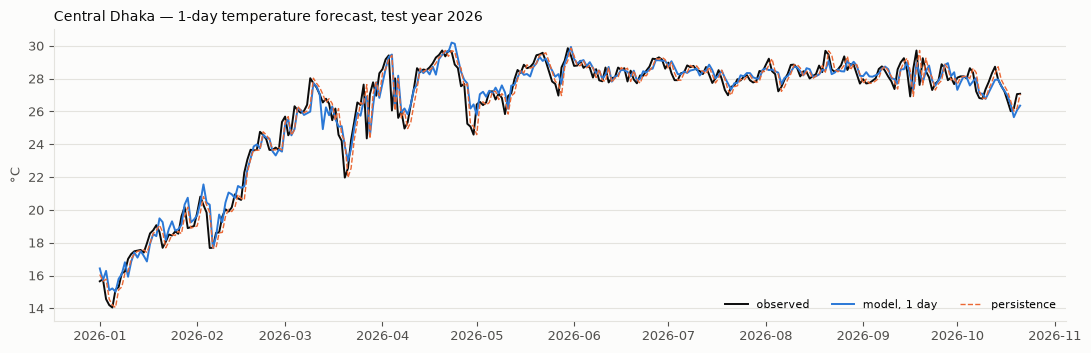

In [6]:
gbr, Xte, yte, persistence = models[1]
pred1 = gbr.predict(Xte)
mask = (daily.loc[Xte.index, "region"] == "Central_Dhaka")
dates = daily.loc[Xte.index, "date"]

fig, ax = plt.subplots(figsize=(11, 3.6))
sel = mask.to_numpy()
ax.plot(dates[sel], yte[sel], color=INK, linewidth=1.4, label="observed")
ax.plot(dates[sel], pred1[sel], color=BLUE, linewidth=1.4, label="model, 1 day")
ax.plot(dates[sel], persistence[sel], color=ORANGE, linewidth=1, linestyle="--", label="persistence")
ax.set_title("Central Dhaka — 1-day temperature forecast, test year 2026", loc="left")
ax.set_ylabel("°C"); ax.grid(axis="y"); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, ncol=3)
fig.tight_layout(); plt.show()

In [7]:
err = np.abs(pred1[sel] - yte[sel].to_numpy())
errp = np.abs(persistence[sel].to_numpy() - yte[sel].to_numpy())
print(f"Central Dhaka, 1-day: model mean abs error {np.nanmean(err):.2f} °C, "
      f"persistence {np.nanmean(errp):.2f} °C")
print(f"3-day RMSE across all regions: {scores[(scores.horizon==3)&(scores.model=='gradient boosting')].RMSE.iloc[0]:.2f} °C")

Central Dhaka, 1-day: model mean abs error 0.53 °C, persistence 0.53 °C
3-day RMSE across all regions: 1.17 °C


## 6. What this is really telling you

- **At 1 day, persistence is hard to beat.** Any gain from the model is small; the value
  of the feature set is mainly in the 3-day horizon, where persistence starts to decay.
- **The 3-day forecast is where a product can honestly claim something**, and even there
  the errors are dominated by synoptic events (rain spells, cold fronts) that these
  features do not resolve.
- **Never present this as a weather forecast.** It is a statistical extrapolation from a
  reanalysis grid cell, not a numerical weather prediction. For an actual forecast, use
  a NWP product (ECMWF/GFS via an API) and keep this as the fallback when offline.
- The panel has ~1,760 days; effective sample size is far smaller because day-to-day
  values are nearly redundant. Treat the last test year as a sanity check, not proof.